# PlacementIQ AI - Data Cleaning
In this notebook, we clean the raw dataset, handle missing values, and visualize & cap outliers using Boxplots.


In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import os

os.makedirs('outputs', exist_ok=True)


## 1. Load Data


In [2]:
df = pd.read_csv('dataset/train.csv')
print(f'Original shape: {df.shape}')
df.head()


Original shape: (45000, 15)


,Student_ID,Age,Gender,Degree,Branch,CGPA,Internships,Projects,Coding_Skills,Communication_Skills,Aptitude_Test_Score,Soft_Skills_Rating,Certifications,Backlogs,Placement_Status
0,1048,22,Female,B.Tech,ECE,6.29,0,3,4,6,51,5,1,3,Not Placed
1,37820,20,Female,BCA,ECE,6.05,1,4,6,8,59,8,2,1,Not Placed
2,49668,22,Male,MCA,ME,7.22,1,4,6,6,58,6,2,2,Not Placed
3,19467,22,Male,MCA,ME,7.78,2,4,6,6,90,4,2,0,Placed
4,23094,20,Female,B.Tech,ME,7.63,1,4,6,5,79,6,2,0,Placed


## 2. Drop Irrelevant Columns & Duplicates


In [3]:
if 'Student_ID' in df.columns:
    df.drop(columns=['Student_ID'], inplace=True)
df.drop_duplicates(inplace=True)
print(f'Shape after dropping duplicates and ID: {df.shape}')


Shape after dropping duplicates and ID: (45000, 14)


## 3. Handle Missing Values


In [4]:
print('Missing values before imputation:')
print(df.isnull().sum())

# Impute numerical with Median, categorical with Mode
num_cols = df.select_dtypes(include=['float64', 'int64']).columns
cat_cols = df.select_dtypes(include=['object']).columns

for col in num_cols:
    df[col].fillna(df[col].median(), inplace=True)
for col in cat_cols:
    df[col].fillna(df[col].mode()[0], inplace=True)

print('\nMissing values after imputation:')
print(df.isnull().sum())


Missing values before imputation:
Age                     0
Gender                  0
Degree                  0
Branch                  0
CGPA                    0
Internships             0
Projects                0
Coding_Skills           0
Communication_Skills    0
Aptitude_Test_Score     0
Soft_Skills_Rating      0
Certifications          0
Backlogs                0
Placement_Status        0
dtype: int64

Missing values after imputation:
Age                     0
Gender                  0
Degree                  0
Branch                  0
CGPA                    0
Internships             0
Projects                0
Coding_Skills           0
Communication_Skills    0
Aptitude_Test_Score     0
Soft_Skills_Rating      0
Certifications          0
Backlogs                0
Placement_Status        0
dtype: int64


C:\Users\Pansh\AppData\Local\Temp\ipykernel_38668\3550771794.py:6: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/user_guide/migration-3-strings.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
  cat_cols = df.select_dtypes(include=['object']).columns
C:\Users\Pansh\AppData\Local\Temp\ipykernel_38668\3550771794.py:9: ChainedAssignmentError: A value is being set on a copy of a DataFrame or Series through chained assignment using an inplace method.
Such inplace method never works to update the original DataFrame or Series, because the intermediate object on which we are setting values always behaves as a copy (due to Copy-on-Write).

For example, when doin

## 4. Feature Boxplots (Outlier Detection)


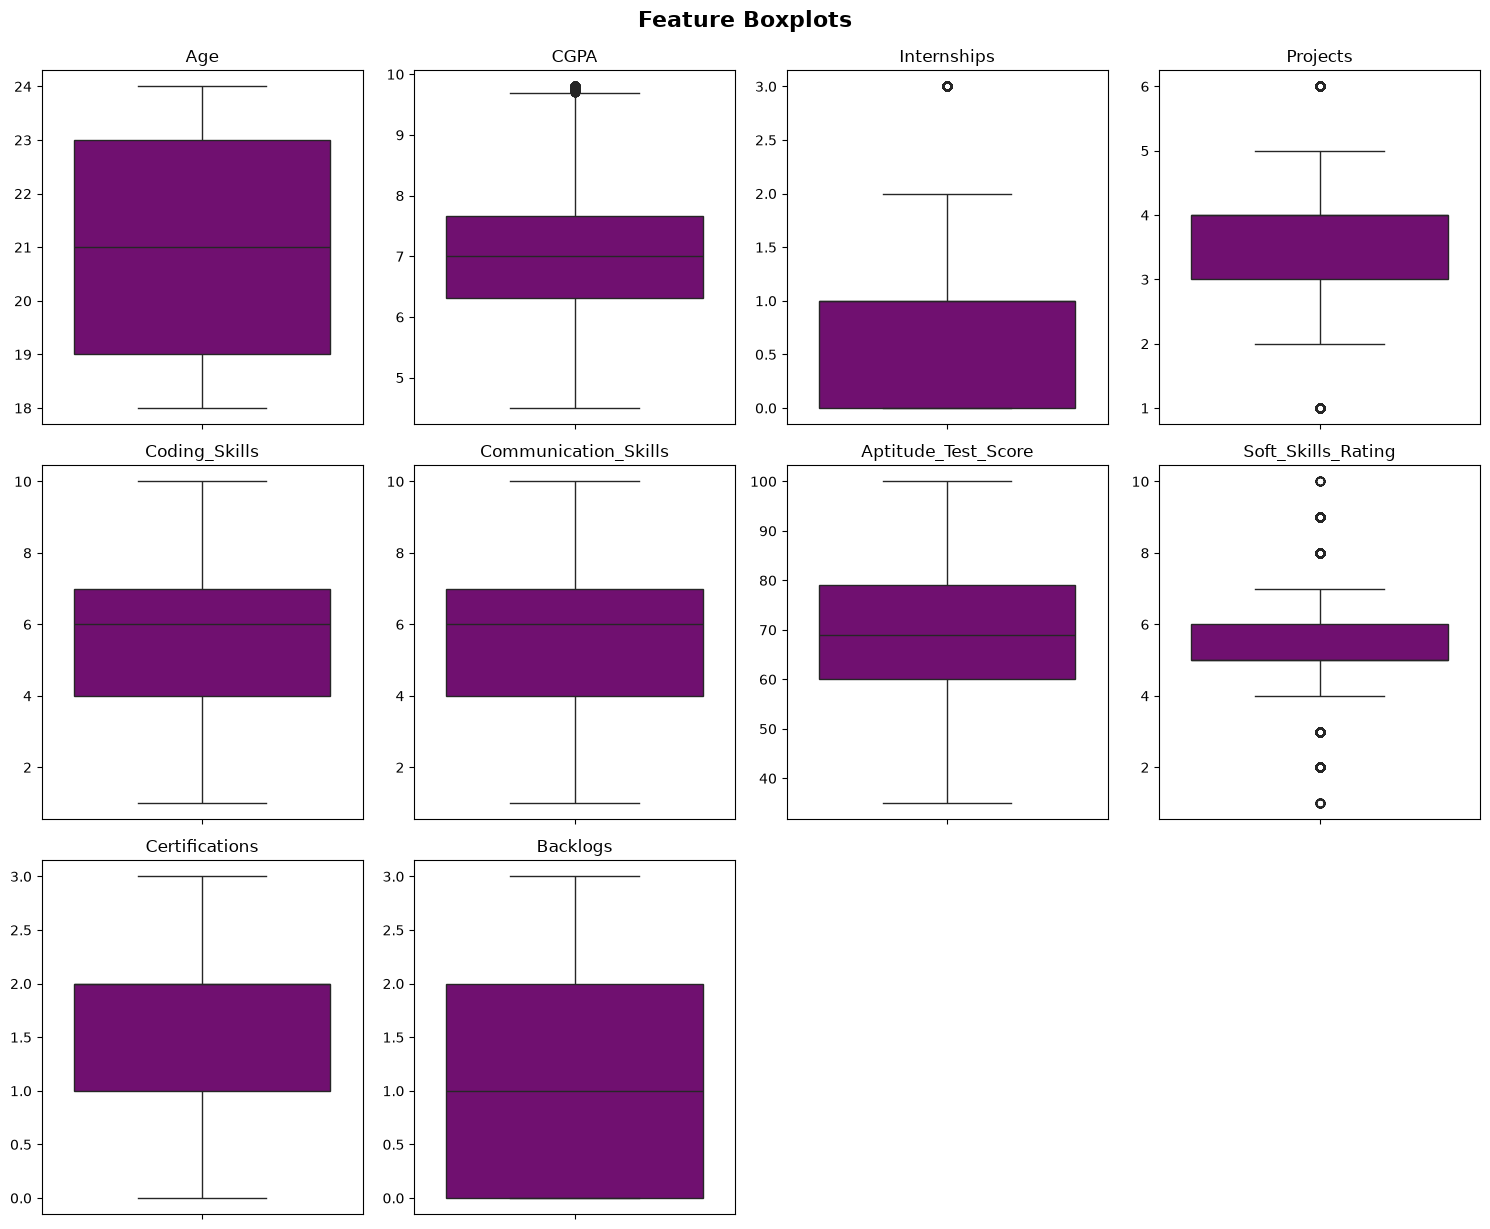

In [5]:
plt.figure(figsize=(15, 12))
features_to_plot = [col for col in num_cols if col != 'Placement_Status']
for i, col in enumerate(features_to_plot, 1):
    plt.subplot(3, 4, i)
    sns.boxplot(y=df[col], color='purple')
    plt.title(col)
    plt.ylabel('')
plt.tight_layout()
plt.suptitle('Feature Boxplots', y=1.02, fontsize=16, fontweight='bold')
plt.savefig('outputs/boxplots.png', bbox_inches='tight')
plt.show()


## 5. Cap Outliers using IQR


In [6]:
for col in features_to_plot:
    Q1 = df[col].quantile(0.25)
    Q3 = df[col].quantile(0.75)
    IQR = Q3 - Q1
    lower_bound = Q1 - 1.5 * IQR
    upper_bound = Q3 + 1.5 * IQR
    df[col] = np.where(df[col] < lower_bound, lower_bound, df[col])
    df[col] = np.where(df[col] > upper_bound, upper_bound, df[col])
print('Outliers capped successfully.')
df.to_csv('dataset/cleaned_train.csv', index=False)


Outliers capped successfully.
